In [465]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score

In [466]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [469]:
dataset_df = dataset.copy()

In [4]:
# dorp the meanless columns
dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

# for Age: replace the nan with the mean value.
dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

# for bill: replace the nan with zero value. 
for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
    
# for category: using the one-hot encoding.
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

In [5]:
# one-hot encoding:
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[name].unique()), dataset_df[name].unique())
    for key in dataset_df[name].unique():
        dataset_df[f'{name}_{key}'] = 0
        dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1
        
    dataset_df.drop(columns=[name], inplace=True)

In [6]:
# split the dataset
dataset_x = dataset_df.drop(columns=['Transported'])
dataset_y = dataset_df['Transported']

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
    stratify=dataset_y
)

In [7]:
dataset['PassengerId'].astype

<bound method NDFrame.astype of 0       0001_01
1       0002_01
2       0003_01
3       0003_02
4       0004_01
         ...   
8688    9276_01
8689    9278_01
8690    9279_01
8691    9280_01
8692    9280_02
Name: PassengerId, Length: 8693, dtype: str>

In [3]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
        
    dataset_df['Cost'] = dataset_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### Decision tree

In [58]:
def sigmoid(x):
#     return 1 / (1 + np.exp(-x))
    return np.exp(x) / (1 + np.exp(x))

def score(F0, forest, y_val):
    F_predict = np.ones(shape=y_val.shape) * F0
    for tree, gamma in forest:
        leaf_id = tree.apply(x_val)
        pre_gamma = np.array([gamma[i] for i in leaf_id])
        F_predict += lr * pre_gamma
    y_predict = sigmoid(F_predict) > 0.5
    
    return accuracy_score(y_val, y_predict)

In [103]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

print(x_train_df.shape)
x_train = np.array(x_train_df)
y_train = np.array(y_train_df)
x_val = np.array(x_val_df)
y_val = np.array(y_val_df)

(6954, 35)


In [97]:
# hyper-parameters
lr = 0.001
samples_num = x_train.shape[0]
iteration = 2000
max_depth = 3
min_samples_leaf = 5

newton_tol = 1e-5
max_newton_ite = 100

# initialize F0
p0 = np.mean(y_train)
F0 = np.log(p0 / (1 - p0))
F = np.ones(shape=(samples_num, )) * F0

forest = []

for i in range(iteration):
    p = sigmoid(F)
    residual = y_train - p

    Tm = DecisionTreeRegressor(criterion='squared_error', 
                               max_depth=max_depth,
                               min_samples_leaf=min_samples_leaf,
                               random_state=42)
    Tm.fit(x_train, residual)

    Tm_final = np.zeros(shape=(samples_num, ))

    # fit gamma
    leaf_id_list = Tm.apply(x_train)
    gamma_dict = {}
    for leaf_id in np.unique(leaf_id_list):
        samples_idx = np.where(leaf_id_list == leaf_id)[0]

        # newton iteration
        tol = 100
        newton_ite = 0
        gamma = 0

        for _ in range(max_newton_ite):
            newton_ite += 1
            
            prob = sigmoid(F[samples_idx] + gamma)
            G = np.sum(prob - y_train[samples_idx])
            
            tol = np.abs(G)
            if tol <= newton_tol:
                break
            
            G_gradient = np.sum(prob * (1 - prob))
            if G_gradient < 1e-12:
                break
                
            gamma -= G / G_gradient

            
        Tm_final[samples_idx] = gamma
        gamma_dict[leaf_id] = gamma
    
    if i % 100 == 0:
        print(f'Finish {i} iteration.')
    F = F + lr * Tm_final
    forest.append((Tm, gamma_dict))

Finish 0 iteration.
Finish 100 iteration.
Finish 200 iteration.
Finish 300 iteration.
Finish 400 iteration.
Finish 500 iteration.
Finish 600 iteration.
Finish 700 iteration.
Finish 800 iteration.
Finish 900 iteration.
Finish 1000 iteration.
Finish 1100 iteration.
Finish 1200 iteration.
Finish 1300 iteration.
Finish 1400 iteration.
Finish 1500 iteration.
Finish 1600 iteration.
Finish 1700 iteration.
Finish 1800 iteration.
Finish 1900 iteration.


In [98]:
len(forest)

2000

In [99]:
F_predict = np.ones(shape=y_val.shape) * F0
for tree, gamma in forest:
    leaf_id = tree.apply(x_val)
    pre_gamma = np.array([gamma[i] for i in leaf_id])
    F_predict += lr * pre_gamma
y_predict = sigmoid(F_predict) > 0.5

In [100]:
y_predict

array([False, False,  True, ..., False,  True, False], shape=(1739,))

In [101]:
accuracy_score(y_val, y_predict)

0.7837837837837838

---

### Analysis

In [107]:
def sigmoid(x):
#     return 1 / (1 + np.exp(-x))
    return np.exp(x) / (1 + np.exp(x))

def predict(F0, forest, x_val):
    F_predict = np.ones(shape=x_val.shape[0]) * F0
    for tree, gamma in forest:
        leaf_id = tree.apply(x_val)
        pre_gamma = np.array([gamma[i] for i in leaf_id])
        F_predict += lr * pre_gamma
    predict_prob = sigmoid(F_predict)
    
    return predict_prob

In [441]:
def gradientBoosting(x_train: np.ndarray, 
                     y_train: np.ndarray, 
                     iteration: int,
                     lr = 0.001, 
                     max_depth = 3, 
                     min_samples_leaf = 5, 
                     newton_tol = 1e-10, 
                     max_newton_ite = 100, 
                     patient = 100
                    ):

    samples_num = x_train.shape[0]
    # initialize F0
    p0 = np.mean(y_train)
    F0 = np.log(p0 / (1 - p0))
    F = np.ones(shape=(samples_num, )) * F0
    F_val = np.ones(shape=(x_val.shape[0], )) * F0

    forest = []
    val_loss_list = []
    train_loss_list = []
    val_score_list = []
    train_score_list = []
    best_val_loss = np.inf
    delta_loss = 1e-5
    best_iteration = 0
    wait = 0
    best_forest = None
    labda = 5
    
    for i in range(iteration):
        p = sigmoid(F)
        residual = y_train - p

        Tm = DecisionTreeRegressor(criterion='squared_error', 
                                   max_depth=max_depth,
                                   min_samples_leaf=min_samples_leaf,
                                   random_state=42)
        Tm.fit(x_train, residual)

        Tm_final = np.zeros(shape=(samples_num, ))

        # fit gamma
        leaf_id_list = Tm.apply(x_train)
        gamma_dict = {}
        for leaf_id in np.unique(leaf_id_list):
            samples_idx = np.where(leaf_id_list == leaf_id)[0]

            # newton iteration
            tol = 100
            newton_ite = 0
            gamma = 0

            for _ in range(max_newton_ite):
                newton_ite += 1

                prob = sigmoid(F[samples_idx] + gamma)
                G = np.sum(prob - y_train[samples_idx])

                tol = np.abs(G)
                if tol <= newton_tol:
                    break

                G_gradient = np.sum(prob * (1 - prob))
                if G_gradient < 1e-12:
                    break

                gamma -= G / (G_gradient + labda)


            Tm_final[samples_idx] = gamma
            gamma_dict[leaf_id] = gamma
#             print(gamma)

        if i % 500 == 0:
            print(f'Finish {i} iteration.')
        F = F + lr * Tm_final
        forest.append((Tm, gamma_dict))

        # monitoring
        val_id = Tm.apply(x_val)
        F_val += lr * np.array([gamma_dict[k] for k in val_id])
        prob_val = sigmoid(F_val)
        y_val_pred = prob_val > 0.5
        val_score_list.append([i, accuracy_score(y_val, y_val_pred)])
        val_loss = - np.mean(y_val.astype(np.int_) * np.log(prob_val) + (1 - y_val.astype(np.int_)) * np.log(1 - prob_val))
        val_loss_list.append([i, val_loss])
        
        prob_train = sigmoid(F)
        y_train_pred = prob_train > 0.5
        train_score_list.append([i, accuracy_score(y_train, y_train_pred)])
        train_loss = - np.mean(y_train.astype(np.int_) * np.log(prob_train) + (1 - y_train.astype(np.int_)) * np.log(1 - prob_train))
        train_loss_list.append([i, train_loss])

        if val_loss < best_val_loss - delta_loss:
            best_val_loss = val_loss
            best_iteration = i
            wait = 0
            best_forest = forest.copy()

        else:
            wait += 1

        if wait >= patient:
            print(f'early stoping in {i} step.')
            print(f'best iteration is {best_iteration}.')
            print(f'best val loss is {best_val_loss}.')
            
            break

    return best_forest, F0, np.array(val_score_list), np.array(train_score_list), np.array(val_loss_list), np.array(train_loss_list), best_iteration, best_val_loss

In [442]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

print(x_train_df.shape)
x_train = np.array(x_train_df)
y_train = np.array(y_train_df)
x_val = np.array(x_val_df)
y_val = np.array(y_val_df)

(6954, 35)


In [453]:
iteration = 8000
lr = 0.05
max_depth = 4
max_newton_ite = 5
min_leaf = 5
forest, F0, val_score_list, train_score_list, val_loss, train_loss, best_iteration, best_val_loss = gradientBoosting(
    x_train, 
    y_train, 
    iteration, 
    lr=lr, 
    max_depth=max_depth,
    min_samples_leaf = min_leaf, 
    newton_tol=1e-3, 
    max_newton_ite=max_newton_ite)

y_predict = predict(F0, forest, x_val)
y_predict = y_predict > 0.5
accuracy_score(y_val, y_predict)

Finish 0 iteration.
early stoping in 415 step.
best iteration is 315.
best val loss is 0.39210444633942115.


0.8004600345025877

lr = 0.05, max_depth = 4
min_leaf = 
3, 284, 0.3940786806622762
4, 357, 0.3949944290229217
5, 320, 0.3929950486414579
6, 309, 0.3948663159992296
7, 260, 0.39565063989391946
8, 243, 0.3968854657074324

lr = 0.05 
max_depth = 
1, 3383, 0.43099138825231875
2, 1073, 0.40354176086737187
3, 485,  0.3959211166824846
4, 320,  0.3929950486414579
5, 211,  0.3956507290363017

0.005, 4342, 0.3979893
0.01, 2158,  0.3982400
0.02, 1216,  0.3966014
0.04, 638,   0.39663421408661786
0.05, 485,   0.3959211166824846
0.08, 363,   0.3971571290266332
0.1,  222,   0.3969254518734677

In [341]:
np.save(f'./analysis/score_list_lr_{lr}_bestloss_{best_val_loss:.5f}_bestite_{best_iteration}_maxdepth_{max_depth}_maxnewtonite_{max_newton_ite}.npy', score_list)
np.save(f'./analysis/val_loss_lr_{lr}_bestloss_{best_val_loss:.5f}_bestite_{best_iteration}_maxdepth_{max_depth}_maxnewtonite_{max_newton_ite}.npy', val_loss)
np.save(f'./analysis/train_loss_lr_{lr}_bestloss_{best_val_loss:.5f}_bestite_{best_iteration}_maxdepth_{max_depth}_maxnewtonite_{max_newton_ite}.npy', train_loss)

In [426]:
np.max([np.max(list(gamma.values())) for _, gamma in forest])

np.float64(5.601786234656118)

In [343]:
val_loss.shape

(1317, 2)

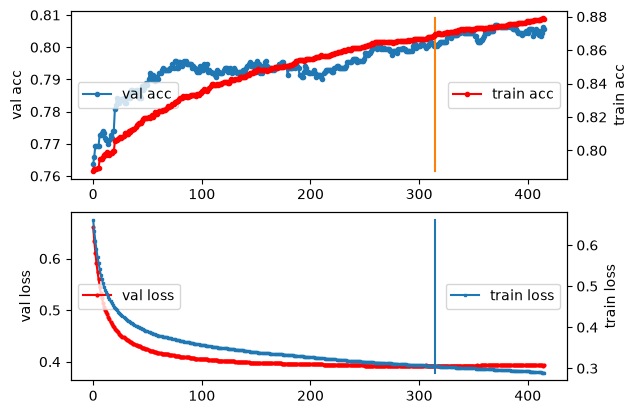

In [476]:
fig, ax = plt.subplots(nrows=2, dpi=100)

start_k = 0

ax[0].plot(val_score_list[start_k:, 0], val_score_list[start_k:, 1], '.-', label='val acc')
ax[0].plot([best_iteration] * 100, np.linspace(*ax[0].get_ylim(), 100))
ax[0].set_ylabel('val acc')
ax[0].legend(loc='center left')

axr = ax[0].twinx()
axr.plot(train_score_list[start_k:, 0], train_score_list[start_k:, 1], '.-', color='r', label='train acc')
axr.set_ylabel('train acc')
axr.legend(loc='center right')


axr = ax[1].twinx()
ax[1].plot(val_loss[start_k:, 0], val_loss[start_k:, 1], marker='o', color='r', markersize=2, label='val loss')
ax[1].set_ylabel('val loss')
ax[1].legend(loc='center left')
ax[1].plot([best_iteration] * 100, np.linspace(*ax[1].get_ylim(), 100))
axr.plot(train_loss[start_k:, 0], train_loss[start_k:, 1], marker='s', markersize=2, label='train loss')
axr.set_ylabel('train loss')
axr.legend(loc='center right')

##### submit

In [455]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(columns=dataset_x.columns, fill_value=0)

In [456]:
test_pred = predict(F0, forest, np.array(test_df))

submit = sample.copy()
submit["Transported"] = (test_pred > 0.5).astype(bool)

In [457]:
submit

,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
...,...,...
4272,9266_02,True
4273,9269_01,True
4274,9271_01,True
4275,9273_01,True


In [458]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [459]:
ls

analysis/                               titanic_alpha_GradientBoosting.ipynb
data/                                   titanic_alpha_logic_registration.ipynb
submit.csv                              titanic_alpha_nueral_network.ipynb
titanic_alpha_AdaBoost.ipynb            titanic_dataset.ipynb
titanic_alpha_CART&RandomForest.ipynb


In [461]:
0.4 + 0.025 * 10

0.65

In [440]:
for tree, _ in forest:
    all_id = tree.apply(x_train)
    
    id_sample, count = np.unique(all_id, return_counts=True)
    print(count)
    print(id_sample)
    for id_leaf, count_leaf in zip(id_sample, count):
        if np.sum(y_train[all_id == id_leaf]) == count_leaf:
            print(id_leaf, count_leaf)
        if np.sum(y_train[all_id == id_leaf]) == 0:
            print('zero', id_leaf, count_leaf)

[1323   32   46  113   33  412  498  441 1824  602  476  176  664  108
   97  109]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
[1323   32   46  113  193  283  483  425 2191  654  481  144  381   65
   77   63]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
zero 30 63
[1323   32   46  113  440    5  498  441 2105  740  491  134  303  143
   77   63]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
zero 12 5
zero 30 63
[1323   32   46  113  100  376  483  425 2279  672  511  185  257   48
   45   59]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
[1323   32   46  113   33  412  498  441 2195  811  537  104  263   42
   55   49]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
zero 30 49
[1220  135   46  113  193  283  483  425 2099  814  536  198  263   42
   45   59]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
[1323   32   46  113  188  366  432  398 1790  598  501  189  674  112
  139   53]
[ 4  5  7  8 11 12 14 15 19 20 22 23 26 27 29 30]
[1220  135   46  113   33 

In [72]:
def test_result(x_val, forest, alpha_list):
    result = np.zeros(shape=(x_val.shape[0], ))
    for k, k_tree in enumerate(forest):
        predict = np.array(k_tree.predict(x_val), dtype=np.int_) * 2 - 1
        result += alpha_list[k] * predict
    
    return result > 0

In [117]:
N = x_train_df.shape[0]
M = 1000
sample_weight = np.ones(N) / N
alpha_list = []
loss = [np.ones(N)]
exp_loss = []
forest = []

val_acc = []
err_list = []
max_weight = []

for epoch in range(M):

#     print(epoch)
    
    tree = DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=42)
    tree.fit(x_train_df, y_train_df, sample_weight=sample_weight)
    forest.append(tree)
    
    predict = tree.predict(x_train_df)
    wrong = predict != np.array(y_train_df)
    err = np.sum(sample_weight[wrong])
    alpha = (1 / 2) * np.log((1 - err) / err)
    
    L_k = np.exp(-alpha * (np.array(y_train_df, dtype=np.int_) * 2 - 1) * (np.array(predict, dtype=np.int_) * 2 - 1))
    loss.append(L_k * loss[-1])

    sample_weight *= L_k
    sample_weight = sample_weight / np.sum(sample_weight).item()
    
    exp_loss.append(np.sum(loss[-1]) / N)
    err_list.append(err)
    alpha_list.append(alpha)
    max_weight.append([np.argsort(sample_weight)[-1], max(sample_weight)])
    
    if epoch % 50 == 0:
        print(epoch)
        y_val = test_result(x_val_df, forest, alpha_list)
        val_acc.append([epoch, accuracy_score(y_val_df, y_val)])

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


Text(0, 0.5, 'max weight index')

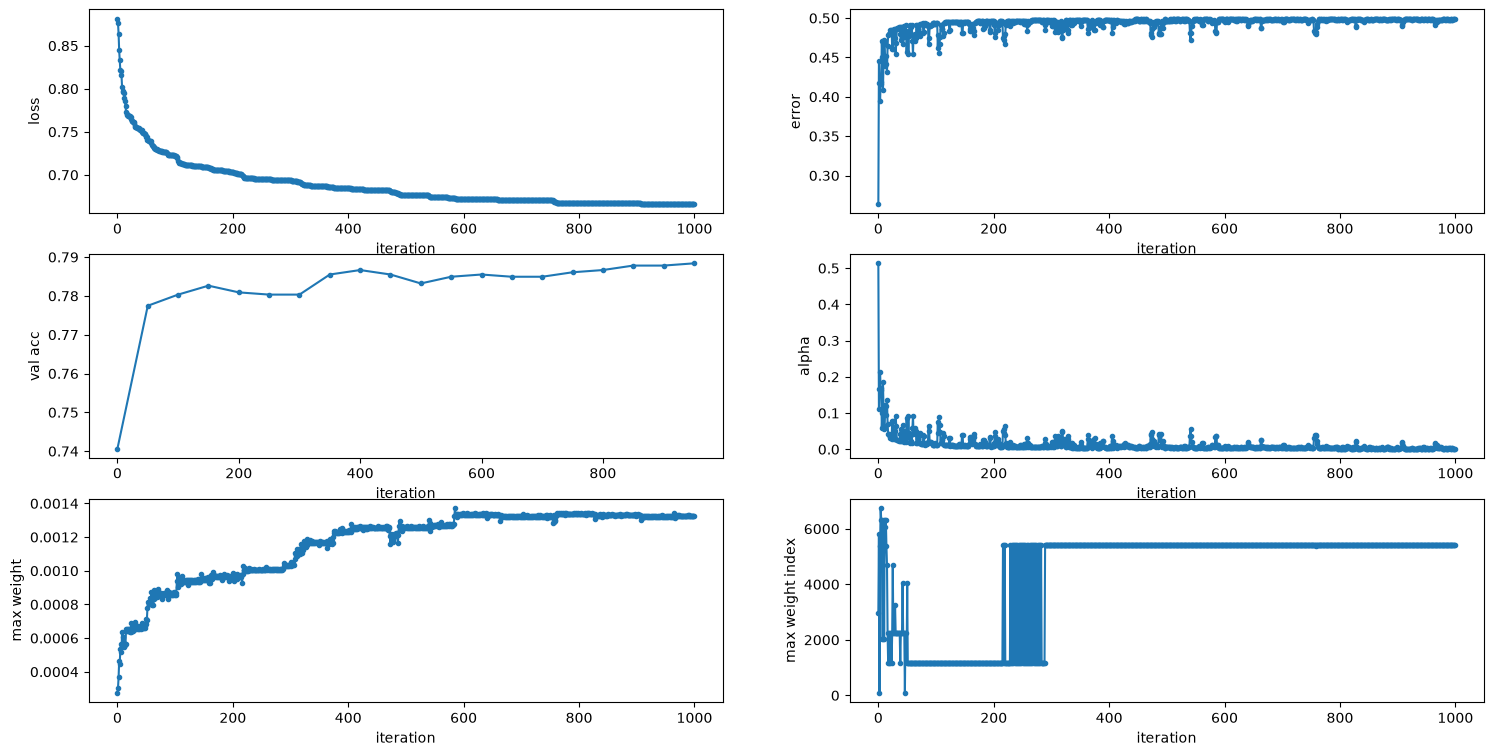

In [121]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(18, 9))

ax[0][0].plot(exp_loss, '.-')
ax[0][0].set_xlabel('iteration')
ax[0][0].set_ylabel('loss')

ax[0][1].plot(err_list, '.-')
ax[0][1].set_xlabel('iteration')
ax[0][1].set_ylabel('error')

ax[1][0].plot(np.array(val_acc)[:, 0], np.array(val_acc)[:, 1], '.-')
ax[1][0].set_xlabel('iteration')
ax[1][0].set_ylabel('val acc')

ax[1][1].plot(alpha_list, '.-')
ax[1][1].set_xlabel('iteration')
ax[1][1].set_ylabel('alpha')

ax[2][0].plot(np.array(max_weight)[:, 1], '.-')
ax[2][0].set_xlabel('iteration')
ax[2][0].set_ylabel('max weight')

ax[2][1].plot(np.array(max_weight)[:, 0], '.-')
ax[2][1].set_xlabel('iteration')
ax[2][1].set_ylabel('max weight index')

In [123]:
np.array(max_weight)[-100:, 0]

array([5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414., 5414.,
       5414.])

In [131]:
x_train_df.iloc[5414]

PassengerId                  8007.0
Age                            24.0
RoomService                     0.0
FoodCourt                       0.0
ShoppingMall                   92.0
Spa                          1492.0
VRDeck                          0.0
Cabin_num                     517.0
Cost                         1584.0
HomePlanet_Europa               0.0
HomePlanet_Earth                1.0
HomePlanet_Mars                 0.0
HomePlanet_Missing              0.0
Destination_TRAPPIST-1e         0.0
Destination_PSO J318.5-22       1.0
Destination_55 Cancri e         0.0
Destination_Missing             0.0
CryoSleep_False                 1.0
CryoSleep_True                  0.0
CryoSleep_Missing               0.0
VIP_False                       1.0
VIP_True                        0.0
VIP_Missing                     0.0
Deck_B                          0.0
Deck_F                          0.0
Deck_A                          0.0
Deck_G                          0.0
Deck_Missing                

In [132]:
dataset.iloc[7485]

PassengerId              8007_02
HomePlanet                 Earth
CryoSleep                  False
Cabin                    E/517/P
Destination        PSO J318.5-22
Age                         24.0
VIP                        False
RoomService                  0.0
FoodCourt                    0.0
ShoppingMall                92.0
Spa                       1492.0
VRDeck                       0.0
Name            Marine Gilleyons
Transported                 True
Name: 7485, dtype: object

##### submit

In [134]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(columns=dataset_x.columns, fill_value=0)

In [135]:
test_pred = test_result(test_df, forest, alpha_list)

submit = sample.copy()
submit["Transported"] = test_pred.astype(bool)

In [136]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [137]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [138]:
ls

data/                                   titanic_alpha_nueral_network.ipynb
submit.csv                              titanic_alpha_tree_model.ipynb
titanic_alpha_AdaBoost.ipynb            titanic_dataset.ipynb
titanic_alpha_logic_registration.ipynb
